# FishSim dolphin–gannet pilot: evidence, model and reproduction

**Run All** verifies 16 completed encounters, regenerates the four figures in the first thesis working draft, and exports four tables. The saved outputs were generated by these cells. Default execution takes **zero native simulation steps**.

This snapshot contains eight development encounters (nearest/exposed policy) and eight fresh exposed-policy replication encounters. It excludes the earlier C policy and later overnight experiments. Two capture streams repeat each fresh starting school: the replication has **two independent schools**, not four.

Start with [README.md](README.md) for local Jupyter installation on Windows, macOS or Linux. Optional execution of the actual frozen model appears at the end and is disabled by default.


In [1]:
from pathlib import Path
import json
import sys

NOTEBOOK_DIR = Path.cwd().resolve()
if not (NOTEBOOK_DIR / "notebook_support.py").is_file():
    raise RuntimeError("Open Jupyter in the folder containing this notebook and notebook_support.py.")
sys.path.insert(0, str(NOTEBOOK_DIR))
import notebook_support as study
print(json.dumps(study.verify_inputs(), indent=2))


{
  "status": "passed",
  "validated_cases": 16,
  "protected_files": 2479,
  "studies": [
    "development: 8 cases",
    "fresh replication: 8 cases"
  ],
  "native_steps": 0
}


## What the model actually assumes

Each dolphin applies local pressure while moving around a tracked prey patch. It may launch one physically feasible strike after **2T of continuous proximity to any currently observed fish within radius 4.5**. It then handles a capture or recovers from a miss and repeats. The proximity clock is not a test that the pod has compacted the school. A fragmented school or isolated reachable fish remains eligible.

`nearest` ranks feasible targets by distance. `exposed` first prefers fewer observed neighbours within radius 2, then interception geometry and distance; this is a preference, not a sparse-fish-only rule. The same policy is used in D and DG. Dolphins do **not** explicitly wait for a bird dive or post-dive scatter in this experiment.

Gannets observe all underwater fish within their depth limit. DBSCAN-style density groups use radius 2 and at least four neighbours including self. A group is selected with probability proportional to accessible population, then a locally dense fish is targeted. Population weighting is distinct from density weighting.

The capture probability **0.7 applies at a resolved physical oral contact**, not per launch or dive. These runs were not calibrated to field dive-success observations; the field categories should not be interpreted as repeated attempts on the same fish. Space and time units are uncalibrated; 36T is not 36 seconds. There is no energy budget, evolutionary learning, numerical convergence claim or demonstration of reciprocal long-term cooperation.


In [2]:
study.print_table(study.actual_parameter_table())


parameter                                    | value  
---------------------------------------------+--------
Initial fish                                 | 160    
Dolphins                                     | 12     
Gannets in DG                                | 3      
Native timestep T                            | 0.00125
Encounter duration T                         | 36     
Continuous proximity requirement T           | 2      
Fish proximity radius                        | 4.5    
Exposed neighbor radius                      | 2      
Dolphin speed                                | 6      
Dolphin sensing radius                       | 25     
Maximum strike duration T                    | 6      
Successful handling T                        | 2      
Miss recovery T                              | 0.75   
Gannet detection depth                       | 12     
Gannet sensing radius (global approximation) | 1e+09  
Conditional oral-contact success             | 0.7    


## The code that implements target choice

These cells print definitions directly from the frozen model files. They do not execute the controller or replace it with pseudocode. The shared launch guard checks reachability and turning feasibility before a fish enters the ranked candidate list.


In [3]:
controller = "research/exposed_replication_2026-11-08/controllers.py"
print(study.source_excerpt(controller, "SimpleHerdStrikePlanner._candidates"))


    def _candidates(self, state, observation, config):
        x = np.asarray(observation.positions, float).reshape(-1, 3)
        v = np.asarray(observation.velocities, float).reshape(-1, 3)
        if not len(x):
            return [], np.empty(0, dtype=int)
        counts = np.asarray(cKDTree(x).query_ball_point(x, NEIGHBOUR_RADIUS,
                            return_length=True))-1
        distances = np.linalg.norm(x-np.asarray(state.position), axis=1)
        rows = []
        for i in np.flatnonzero(distances <= self.parameters.launch_radius):
            eligible, guard = shared_launch_guard(state, x[i], v[i], config,
                                                   self.parameters.launch_radius)
            if eligible:
                rows.append((int(i), guard))
        if self.policy == 'nearest':
            rows.sort(key=lambda r: (float(distances[r[0]]), observation.prey_ids[r[0]]))
        else:
            rows.sort(key=lambda r: (int(counts[r[0]]),
                r

The cycle implementation below shows the actual pressure reset, 2T threshold, one-strike launch and recovery handling. `memory.maintenance_started` stores the pressure clock. Only committed transitions are subsequently logged.


In [4]:
print(study.source_excerpt(controller, "SimpleHerdStrikePlanner._resolve"))


    def _resolve(self, memory, state, observation, config, events, phase_events, seen_at):
        diagnostic = dict(policy=VERSION, cycle_policy=self.policy, actor_id=state.actor_id,
            time=state.time, observation_time=seen_at, observed_count=len(observation.prey_ids),
            launch_allowed=False, launch_reason='pressure_not_ready', current_patch=False,
            actual_proximity=False, pressure_started=memory.maintenance_started,
            pressure_elapsed=0., target_id=state.target_id,
            selected_neighbor_count=None, feasible_min_neighbor_count=None, feasible_count=0)
        if state.mode == 'attack':
            diagnostic['launch_reason'] = 'active_bout'
            return memory, state, None, diagnostic
        if state.mode == 'recovery':
            if memory.phase != 'recovery':
                memory = self._recovery_memory(memory, state.mode_since)
            if state.time < state.ready_at-EPSILON:
                diagnostic['launch_reason'] = 

The actual gannet target-selection function uses its own recorded random stream. Its cluster draw and final target can be replayed from the sealed bird-event logs.


In [5]:
gannet = "research/exposed_replication_2026-11-08/gannet.py"
print(study.source_excerpt(gannet, "select_dense_target"))


def select_dense_target(state, observation, config, *, rng=None):
    """Sample a dense cluster by accessible fish count, then aim at its density peak.

    The planner supplies its private target RNG. A fixed default seed makes this
    standalone helper reproducible for diagnostics. Accessibility is a coarse
    current-position travel/depth check, never a guarantee of mouth contact.
    Full observation is provided by the builder's global sensing radius; the
    inherited underwater detection-depth restriction is retained.
    """
    rng = np.random.default_rng(0) if rng is None else rng
    local = observe(state, observation.positions, observation.velocities,
                    np.asarray(observation.prey_ids, dtype=np.int64), config)
    x = np.asarray(local.positions, dtype=float).reshape(-1, 3)
    ids = np.asarray(local.prey_ids, dtype=np.int64)
    patches, labels = dense_clusters(x)
    depth_limit = config.max_dive_depth - config.speed / config.turn_rate - config.ascent_ma

## Recalculate the outcomes from the sealed evidence

Captures below are counted from successful physical oral events, checked for unique prey IDs, and reconciled with each completed summary. All cases are 36T, with 28,800 native steps each. The existing paper tables are independently checked against these reconstructed counts.


In [6]:
rows = study.case_rows()
development = study.paired_rows(rows, "development")
replication = study.paired_rows(rows, "replication")
study.print_table(rows, ["study", "school", "capture_seed", "policy", "presence", "dolphin_captures", "gannet_captures", "dolphin_launches", "captures_per_launch"])


study       | school   | capture_seed | policy  | presence | dolphin_captures | gannet_captures | dolphin_launches | captures_per_launch
------------+----------+--------------+---------+----------+------------------+-----------------+------------------+--------------------
development | 39061001 | 61001        | exposed | D        | 22               | 0               | 56               | 0.3929             
development | 39061001 | 61001        | exposed | DG       | 22               | 9               | 54               | 0.4074             
development | 39061001 | 61001        | nearest | D        | 26               | 0               | 52               | 0.5                
development | 39061001 | 61001        | nearest | DG       | 28               | 6               | 52               | 0.5385             
development | 39061002 | 61001        | exposed | D        | 19               | 0               | 46               | 0.413              
development | 39061002 | 61001        | e

Development comparisons selected the exposed policy for fresh follow-up. They remain a separate exploratory set.


In [7]:
study.print_table(development, ["school", "policy", "D", "DG", "difference", "change_percent"])


school   | policy  | D  | DG | difference | change_percent
---------+---------+----+----+------------+---------------
39061001 | exposed | 22 | 22 | 0          | 0             
39061001 | nearest | 26 | 28 | 2          | 7.692         
39061002 | exposed | 19 | 26 | 7          | 36.84         
39061002 | nearest | 29 | 25 | -4         | -13.79        


The fresh comparisons preserve each school and capture stream. The following school means average only the two stochastic repetitions belonging to that school. No confidence interval or significance test is justified by two independent fresh schools.


In [8]:
study.print_table(replication, ["school", "capture_seed", "D", "DG", "difference", "change_percent"])
study.print_table(study.school_means(replication))
total_D = sum(row["D"] for row in replication)
total_DG = sum(row["DG"] for row in replication)
print(f"Fresh descriptive totals: {total_D} → {total_DG}; change {100*(total_DG-total_D)/total_D:.2f}%.")


school   | capture_seed | D  | DG | difference | change_percent
---------+--------------+----+----+------------+---------------
39063501 | 61001        | 23 | 24 | 1          | 4.348         
39063501 | 61002        | 20 | 24 | 4          | 20            
39063502 | 61001        | 22 | 23 | 1          | 4.545         
39063502 | 61002        | 22 | 30 | 8          | 36.36         
school   | repeated_streams | mean_D | mean_DG | mean_difference | positive_repetitions
---------+------------------+--------+---------+-----------------+---------------------
39063501 | 2                | 21.5   | 24      | 2.5             | 2                   
39063502 | 2                | 22     | 26.5    | 4.5             | 2                   
Fresh descriptive totals: 87 → 101; change 16.09%.


## Rebuild all four paper figures

This executes the preserved paper figure source against the bundled sealed data. Figures are saved as PDF and PNG with source-hash receipts under `outputs/figures/`. These are the first working draft figures; future overnight results are not silently mixed into this snapshot.


In [9]:
figure_folder = study.reproduce_figures()


fig1_model
fig2_development
fig3_replication
fig4_mechanism


Figure 1. Model rules and an actual recorded dolphin–gannet encounter snapshot. The trajectories and capture locations come from sealed data.


Figure written: outputs/figures/fig1_model.png


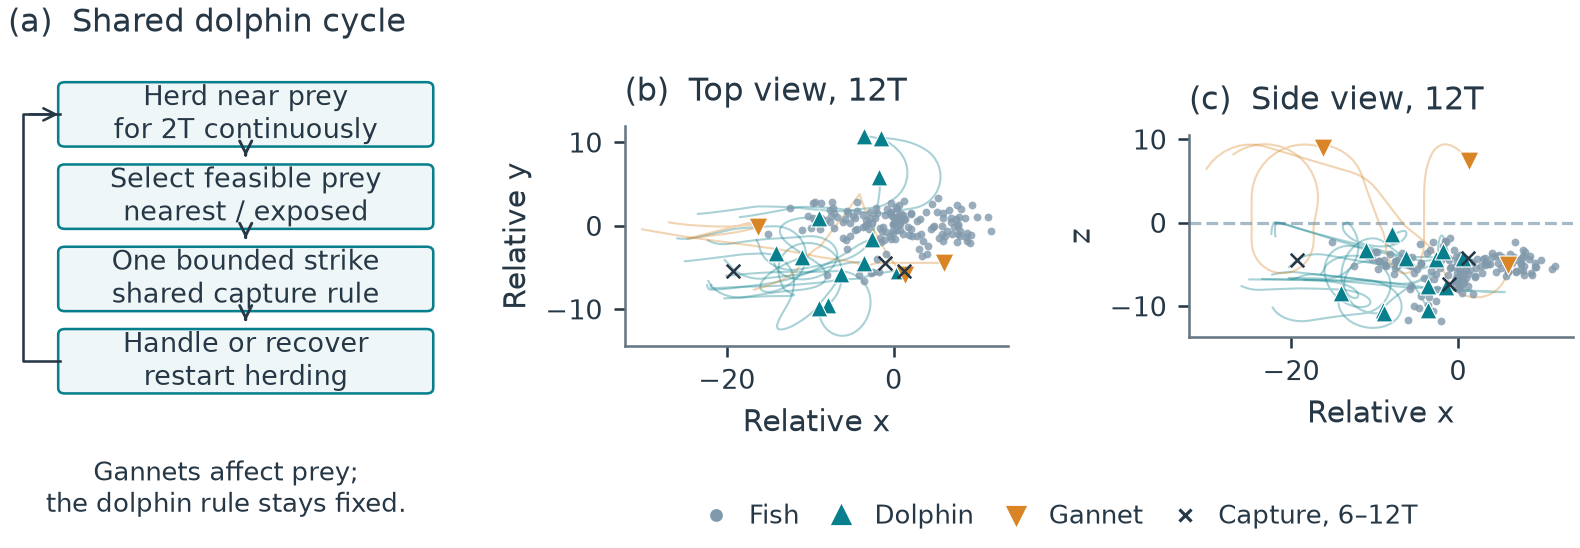

In [10]:
study.show_figure("fig1_model")


Figure 2. Development comparison: nearest and exposed policies across two starting schools. The exposed policy was selected using these exploratory results.


Figure written: outputs/figures/fig2_development.png


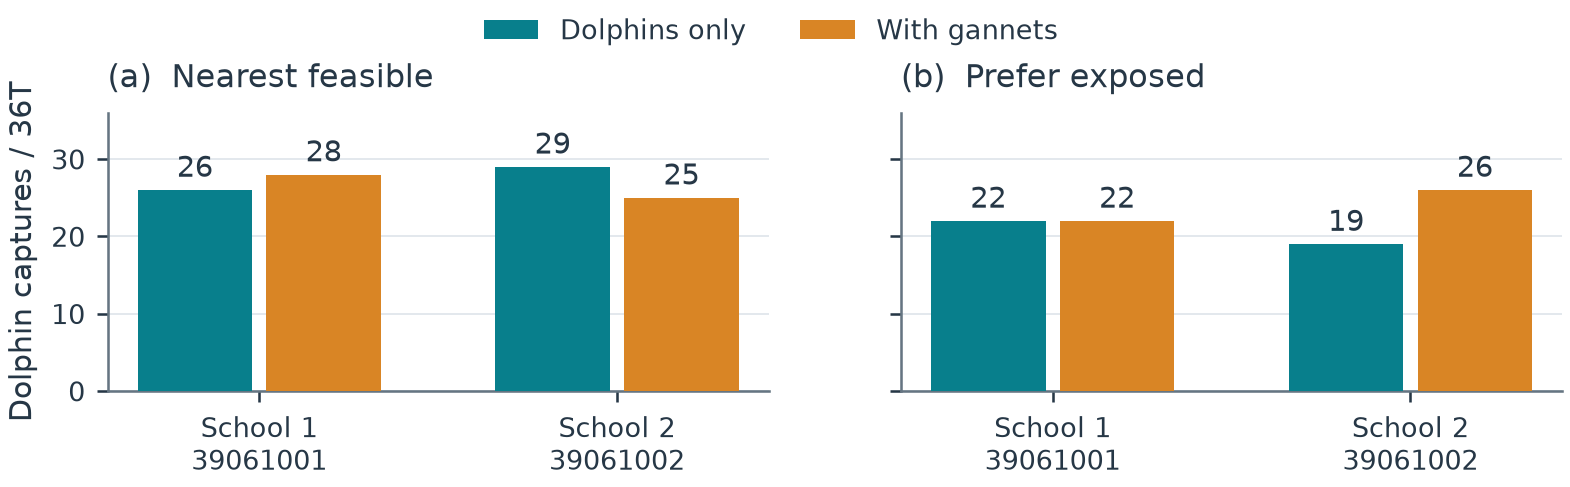

In [11]:
study.show_figure("fig2_development")


Figure 3. Fresh exposed-policy replication: four paired stochastic runs nested within two independent starting schools. Every paired difference is positive here; this remains a small descriptive pilot.


Figure written: outputs/figures/fig3_replication.png


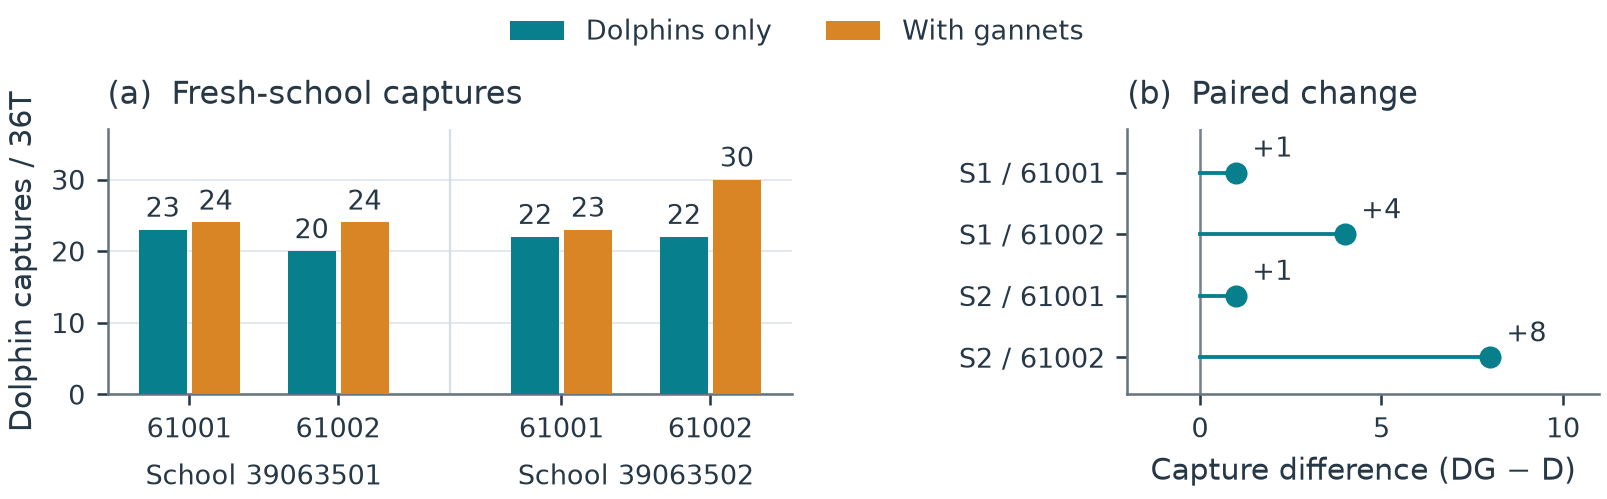

In [12]:
study.show_figure("fig3_replication")


Figure 4. Development launch counts and realized capture yield. Captures per launch incorporate failed pursuit/contact and recovery; they are distinct from the fixed conditional oral-contact probability.


Figure written: outputs/figures/fig4_mechanism.png


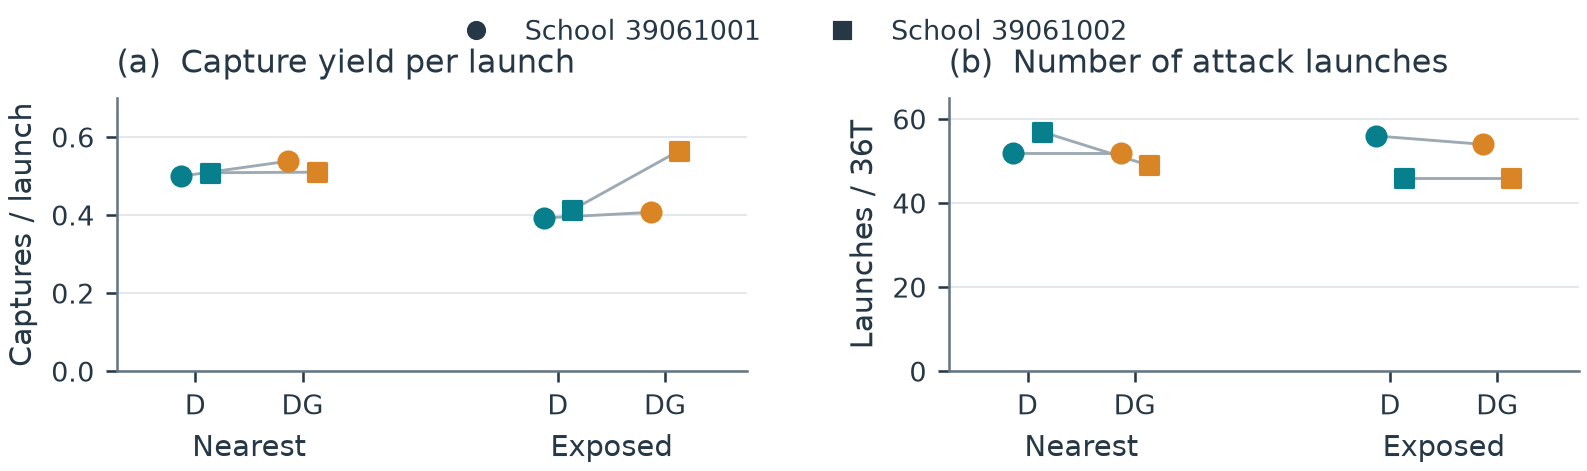

In [13]:
study.show_figure("fig4_mechanism")


In [14]:
study.export_tables(rows, development, replication)


Four tables exported to outputs/tables


## Optional: run the actual frozen model locally

This final section is **off by default**. The static report below imports no native code. Read [NATIVE_SETUP.md](NATIVE_SETUP.md) before switching it on. The supplied binary requires CPython 3.12 on Linux x86-64 with glibc ≥2.43 and compatible C++/OpenMP libraries. The analysis above works independently of this requirement. Source and the real CMake recipe are included; another-platform rebuild is not validated and is intentionally rejected by the historical binary pin.

`QUICK_RUN=True` runs 0.5T D and 0.5T DG sequentially using actual prepared fish checkpoints and the actual coupled simulator. This is an integration check, **too short for the 2T cycle**, and supplies no feeding-benefit evidence. Set `QUICK_RUN=False` for a 36T matched pair. `FULL_REPLICATION=True` requests all eight 36T fresh-replication cases. New results are saved separately; the bundled evidence remains unchanged.


In [15]:
print(json.dumps(study.native_environment(), indent=2))


{
  "python": "3.12.13",
  "system": "Linux",
  "machine": "x86_64",
  "libc": "glibc 2.43",
  "eligible_for_native_import_check": true,
  "native_loaded": false,
  "native_steps": 0,
  "binary_sha256": "eb8654a520304cc429aced67c7e3706db8d2ef1449c5e1327a682a479b10a558",
  "note": "An explicit optional run also checks the actual native import and dependent libraries. Analysis and figures do not need this binary."
}


In [16]:
RUN_MODEL = False
QUICK_RUN = True
FULL_REPLICATION = False
SCHOOL_SEED = 39063501       # or 39063502
CAPTURE_SEED = 61001        # or 61002
WORKERS = 1                # up to 4 for the full eight-case replication

if RUN_MODEL:
    import subprocess
    from datetime import datetime
    output = NOTEBOOK_DIR / "outputs" / "model_runs" / datetime.now().strftime("%Y%m%d_%H%M%S")
    command = [sys.executable, str(NOTEBOOK_DIR / "run_model.py"),
               "--quick" if QUICK_RUN else "--full", "--school", str(SCHOOL_SEED),
               "--capture-seed", str(CAPTURE_SEED), "--workers", str(WORKERS), "--output", str(output)]
    if FULL_REPLICATION:
        if QUICK_RUN:
            raise ValueError("Full replication requires QUICK_RUN=False.")
        command.append("--all-replication")
    subprocess.run(command, check=True, cwd=NOTEBOOK_DIR)
    study.print_table(study.new_run_table(output))
else:
    print("Optional simulation not executed. Default analysis used zero native steps.")


Optional simulation not executed. Default analysis used zero native steps.
